# Flooded Area Mapping from Sentinel-1 Satellite Images
**Individual project | Sen1Floods11 v1.1 | Google Colab**

Comparison: **SAR VH threshold baseline**, **compact U-Net trained from scratch**, and **ResNet18 encoder U-Net with ImageNet pretraining**. Outputs include pixel-level IoU, Dice, confusion matrices, classification reports, loss/accuracy curves, overlays, and reproducible model comparison.

Dataset: [Official Sen1Floods11](https://github.com/cloudtostreet/Sen1Floods11). Its `LabelHand` masks identify **water (1)**, **non-water (0)** and **invalid (-1)**; masks alone cannot distinguish new floodwater from permanent water. The report must describe this as *water/flood inundation mapping* and acknowledge this limitation. The dataset has **446 hand-labelled 512×512 chips**. Do not claim these are all flooded.

**Run on Colab with GPU:** Runtime → Change runtime type → T4 GPU, then Run all. Download ~700 MB (plus pretrained weights) and training may take time. Adjust `EPOCHS` as appropriate and report actual settings/results.

In [1]:
%pip -q install rasterio scikit-learn segmentation-models-pytorch pandas matplotlib tqdm google-cloud-storage

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 4.9 MB/s eta 0:00:00


## 1. Configuration and reproducibility

In [2]:
import os, re, csv, gc, random, json, shutil, subprocess
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import rasterio
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from sklearn.metrics import confusion_matrix, classification_report
from tqdm.auto import tqdm
import segmentation_models_pytorch as smp
from google.cloud import storage

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
ROOT = Path('/content/flood_mapping') if Path('/content').exists() else Path('./flood_mapping')
DATA = ROOT/'data'; OUT = ROOT/'outputs'; OUT.mkdir(parents=True, exist_ok=True)
SIZE=256; BATCH_SIZE=8; EPOCHS=12; LR=3e-4; NUM_WORKERS=2
print('Device:', DEVICE, '| Output:', OUT)

Device: cuda | Output: /content/flood_mapping/outputs


## 2. Download public hand-labelled imagery and official splits

Uses public anonymous Google Cloud Storage reads; no personal API key needed. The original imagery is **2-band SAR (VV, VH)**, not RGB. We use public `gs://sen1floods11/v1.1/...` files without downloading the weak labels or Sentinel-2 bands.

In [3]:
BUCKET='sen1floods11'
PREFIX='v1.1/data/flood_events/HandLabeled/'
client = storage.Client.create_anonymous_client()
bucket=client.bucket(BUCKET)
def download_prefix(prefix, directory):
    directory.mkdir(parents=True,exist_ok=True)
    blobs=list(client.list_blobs(BUCKET,prefix=prefix))
    files=[x for x in blobs if x.name.lower().endswith(('.tif','.csv'))]
    print('Found',len(files),'files in',prefix)
    if not files: raise RuntimeError('No objects found; check cloud bucket access/path.')
    for x in tqdm(files,desc=directory.name):
        dest=directory/Path(x.name).name
        if not dest.exists() or dest.stat().st_size != x.size:
            x.download_to_filename(str(dest))
    return files

split_files=download_prefix('v1.1/splits/flood_handlabeled/',DATA/'splits')
image_files=download_prefix(PREFIX+'S1Hand/',DATA/'S1Hand')
mask_files=download_prefix(PREFIX+'LabelHand/',DATA/'LabelHand')
print('Downloaded imagery:',len(image_files),'masks:',len(mask_files))

Found 4 files in v1.1/splits/flood_handlabeled/


splits:   0%|          | 0/4 [00:00<?, ?it/s]

Found 446 files in v1.1/data/flood_events/HandLabeled/S1Hand/


S1Hand:   0%|          | 0/446 [00:00<?, ?it/s]

Found 446 files in v1.1/data/flood_events/HandLabeled/LabelHand/


LabelHand:   0%|          | 0/446 [00:00<?, ?it/s]

Downloaded imagery: 446 masks: 446


## 3. Read official train / validation / test splits; check image–mask pairing

In [4]:
print('Official CSVs:',[p.name for p in (DATA/'splits').glob('*.csv')])
for f in sorted((DATA/'splits').glob('*.csv')):
    print('\n',f.name, '\n',f.read_text().splitlines()[:3])

# Official split rows often include full filenames. Match by image filename or chip identity.
def core_id(path_or_name):
    name=Path(str(path_or_name)).stem
    return re.sub(r'_(S1Hand|LabelHand|S2Hand)$','',name,flags=re.I)
images={core_id(p):p for p in (DATA/'S1Hand').glob('*.tif')}
masks={core_id(p):p for p in (DATA/'LabelHand').glob('*.tif')}
paired={k:(images[k],masks[k]) for k in images.keys()&masks.keys()}
print('Pairs found:',len(paired))
assert len(paired)>0,'Image/mask pairing failed.'

def get_split_file(split):
    names={'train':['flood_train_data.csv','train.csv'], 'valid':['flood_valid_data.csv','val.csv','valid.csv'], 'test':['flood_test_data.csv','test.csv']}
    paths=list((DATA/'splits').glob('*.csv'))
    for pattern in names[split]:
        p=next((p for p in paths if p.name.lower()==pattern),None)
        if p:return p
    p=next((p for p in paths if split in p.name.lower()),None)
    if p:return p
    raise FileNotFoundError('Missing official '+split+' CSV in '+str(paths))

def read_pairs(split):
    p=get_split_file(split)
    selected=[]
    with p.open(newline='') as fh:
        rows=list(csv.reader(fh))
    for row in rows:
        keys={core_id(v) for v in row if isinstance(v,str) and v.lower().strip().endswith('.tif')}
        # Rows might include extra metadata / no extension. Search for an explicit chip ID if needed.
        if not keys:
            raw=' '.join(row)
            keys={k for k in paired if k in raw}
        for k in sorted(keys):
            if k in paired and k not in {core_id(x[0]) for x in selected}:
                selected.append(paired[k])
    if not selected:
        raise ValueError('Could not parse '+str(p)+'; inspect printed CSV rows and adapt parser.')
    return selected

splits={x:read_pairs(x) for x in ('train','valid','test')}
ids={s:{core_id(im) for im,_ in pairs} for s,pairs in splits.items()}
assert not (ids['train']&ids['valid'] or ids['train']&ids['test'] or ids['valid']&ids['test']),'Overlapping split IDs!'
print({s:len(v) for s,v in splits.items()})
assert sum(map(len,splits.values()))<=len(paired)
pd.DataFrame({'split':list(splits),'image_count':[len(splits[s]) for s in splits]}).to_csv(OUT/'split_counts.csv',index=False)

Official CSVs: ['flood_train_data.csv', 'flood_valid_data.csv', 'flood_test_data.csv', 'flood_bolivia_data.csv']

 flood_bolivia_data.csv 
 ['Bolivia_103757_S1Hand.tif,Bolivia_103757_LabelHand.tif', 'Bolivia_129334_S1Hand.tif,Bolivia_129334_LabelHand.tif', 'Bolivia_195474_S1Hand.tif,Bolivia_195474_LabelHand.tif']

 flood_test_data.csv 
 ['Ghana_313799_S1Hand.tif,Ghana_313799_LabelHand.tif', 'Ghana_1078550_S1Hand.tif,Ghana_1078550_LabelHand.tif', 'Ghana_97059_S1Hand.tif,Ghana_97059_LabelHand.tif']

 flood_train_data.csv 
 ['Ghana_103272_S1Hand.tif,Ghana_103272_LabelHand.tif', 'Ghana_24858_S1Hand.tif,Ghana_24858_LabelHand.tif', 'Ghana_147015_S1Hand.tif,Ghana_147015_LabelHand.tif']

 flood_valid_data.csv 
 ['Ghana_5079_S1Hand.tif,Ghana_5079_LabelHand.tif', 'Ghana_895194_S1Hand.tif,Ghana_895194_LabelHand.tif', 'Ghana_868803_S1Hand.tif,Ghana_868803_LabelHand.tif']
Pairs found: 446
{'train': 252, 'valid': 89, 'test': 90}


## 4. Dataset preprocessing, augmentation and class distribution

`-1` is **ignored**, not treated as non-water. Images use a documented fixed SAR dB clipping range, with bilinear resizing. Masks use **nearest neighbor** to preserve class IDs. Train-only horizontal/vertical flipping and 90° rotations keep the image and label aligned.

Count train pixels:   0%|          | 0/252 [00:00<?, ?it/s]

Train pixel counts, non-water, water, invalid: [12963114  1362418  2189540]


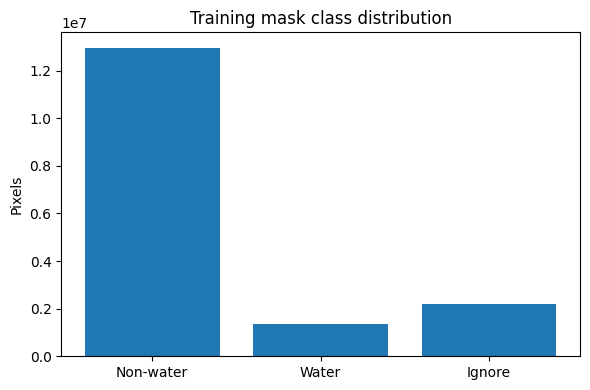

In [5]:
class FloodDataset(Dataset):
    def __init__(self,pairs,augment=False): self.pairs=pairs; self.augment=augment
    def __len__(self):return len(self.pairs)
    def __getitem__(self,idx):
        ip,mp=self.pairs[idx]
        with rasterio.open(ip) as f: image=f.read()[:2].astype('float32')
        with rasterio.open(mp) as f: mask=f.read(1).astype('int16')
        image=np.nan_to_num(image,nan=-50.,posinf=1.,neginf=-50.)
        image=np.clip(image,-50.,1.); image=(image+50.)/51.
        x=torch.from_numpy(image.copy()).float()
        y=torch.from_numpy(mask.astype('int64',copy=True))[None].float()
        x=F.interpolate(x[None],size=(SIZE,SIZE),mode='bilinear',align_corners=False)[0]
        y=F.interpolate(y[None],size=(SIZE,SIZE),mode='nearest')[0,0].long()
        if self.augment:
            if random.random()<.5: x=x.flip(-1); y=y.flip(-1)
            if random.random()<.5: x=x.flip(-2); y=y.flip(-2)
            k=random.randrange(4); x=torch.rot90(x,k,(-2,-1)); y=torch.rot90(y,k,(-2,-1))
        return x,y
train_ds=FloodDataset(splits['train'],True)
train_eval_ds=FloodDataset(splits['train'])
val_ds=FloodDataset(splits['valid'])
test_ds=FloodDataset(splits['test'])
train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,num_workers=NUM_WORKERS)
val_loader=DataLoader(val_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS)
test_loader=DataLoader(test_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS)
counts=np.zeros(3,dtype='int64')
for _,m in tqdm(train_eval_ds,desc='Count train pixels'):
    for i,c in enumerate((0,1,-1)): counts[i]+=int((m==c).sum())
print('Train pixel counts, non-water, water, invalid:',counts)
pd.DataFrame({'label':['Non-water','Water','Ignore (-1)'],'pixels':counts}).to_csv(OUT/'class_distribution.csv',index=False)
plt.figure(figsize=(6,4));plt.bar(['Non-water','Water','Ignore'],counts);plt.ylabel('Pixels');plt.title('Training mask class distribution');plt.tight_layout();plt.savefig(OUT/'class_distribution.png',dpi=180);plt.show()

## 5. Show SAR input and ground truth

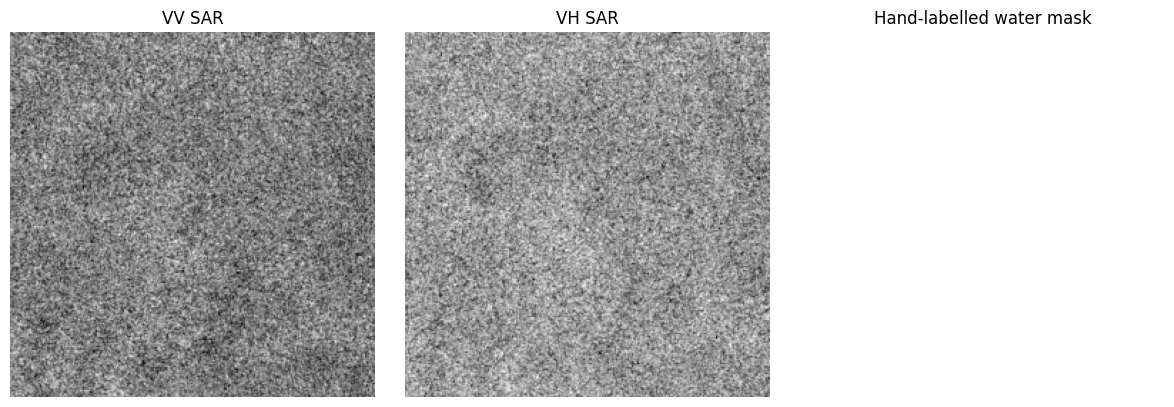

In [6]:
x,y=val_ds[0]
fig,axs=plt.subplots(1,3,figsize=(12,4))
axs[0].imshow(x[0],cmap='gray');axs[0].set_title('VV SAR')
axs[1].imshow(x[1],cmap='gray');axs[1].set_title('VH SAR')
axs[2].imshow(np.ma.masked_where(y.numpy()==-1,y.numpy()),vmin=0,vmax=1,cmap='Blues');axs[2].set_title('Hand-labelled water mask')
for a in axs:a.axis('off')
plt.tight_layout();plt.savefig(OUT/'sample_dataset.png',dpi=180);plt.show()

## 6. Compact CNN and pretrained transfer learning model

In [7]:
# Same U-Net decoder family; encoder varies from scratch to ImageNet-pretrained.
# The pretrained network accepts two SAR bands via segmentation_models_pytorch input-channel adaptation.
models={
  'compact_unet': smp.Unet(encoder_name='resnet18',encoder_weights=None,in_channels=2,classes=1,encoder_depth=4,decoder_channels=(128,64,32,16)),
  'transfer_unet': smp.Unet(encoder_name='resnet18',encoder_weights='imagenet',in_channels=2,classes=1,encoder_depth=4,decoder_channels=(128,64,32,16))
}
for name,model in models.items():
 print(name,'parameters:',sum(p.numel() for p in model.parameters()))

# Mask -1 pixels out of loss and metrics.
def loss_fn(logits,target):
    good=(target!=-1)
    if not good.any(): return logits.sum()*0
    truth=(target==1).float()[:,None]
    loss=F.binary_cross_entropy_with_logits(logits,truth,reduction='none')[:,0]
    return loss[good].mean()

def accumulate_confusion(logits,y):
    pred=(torch.sigmoid(logits[:,0])>=.5)
    valid=(y!=-1)
    truth=(y==1)
    return np.array([int(((~pred)&(~truth)&valid).sum()),int((pred&(~truth)&valid).sum()),int(((~pred)&truth&valid).sum()),int((pred&truth&valid).sum())],dtype=np.int64)

def scores(c):
    tn,fp,fn,tp=map(int,c)
    safe=lambda n,d: n/d if d else 0.
    return {'accuracy':safe(tp+tn,tp+tn+fp+fn),'precision':safe(tp,tp+fp),'recall':safe(tp,tp+fn),
            'f1_dice':safe(2*tp,2*tp+fp+fn),'iou':safe(tp,tp+fp+fn),'tn':tn,'fp':fp,'fn':fn,'tp':tp}

def run_epoch(model,loader,optimizer=None):
    training=optimizer is not None
    model.train(training)
    losses=[]; conf=np.zeros(4,dtype=np.int64)
    for x,y in tqdm(loader,leave=False):
        x,y=x.to(DEVICE),y.to(DEVICE)
        with torch.set_grad_enabled(training):
            logits=model(x); loss=loss_fn(logits,y)
            if training:
                optimizer.zero_grad(set_to_none=True);loss.backward();optimizer.step()
        losses.append(loss.item());conf+=accumulate_confusion(logits.detach(),y)
    return float(np.mean(losses)),scores(conf)


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

compact_unet parameters: 11964753
transfer_unet parameters: 11964753


## 7. Train both networks; save best validation-IoU weights and curves


Training: compact_unet


  0%|          | 0/32 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]

compact_unet epoch 1/12: train loss 0.5113, val loss 0.4030, val IoU 0.0088, val Dice 0.0174


  0%|          | 0/32 [00:00<?, ?it/s]

...

  0%|          | 0/12 [00:00<?, ?it/s]

compact_unet epoch 11/12: train loss 0.1565, val loss 0.1854, val IoU 0.5930, val Dice 0.7445


  0%|          | 0/32 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]

compact_unet epoch 12/12: train loss 0.1526, val loss 0.1440, val IoU 0.5922, val Dice 0.7439


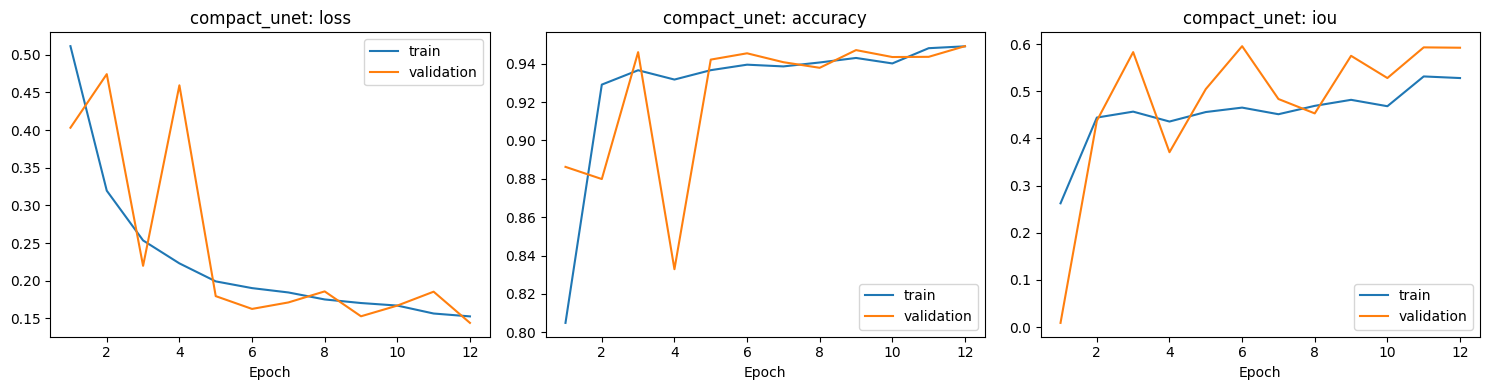


Training: transfer_unet


  0%|          | 0/32 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a447bdef240>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a447bdef240>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

transfer_unet epoch 1/12: train loss 0.7086, val loss 0.4842, val IoU 0.4569, val Dice 0.6272


...

  0%|          | 0/32 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a447bdef240>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a447bdef240>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  0%|          | 0/12 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a447bdef240>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a447bdef240>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

transfer_unet epoch 12/12: train loss 0.1544, val loss 0.1437, val IoU 0.5657, val Dice 0.7226


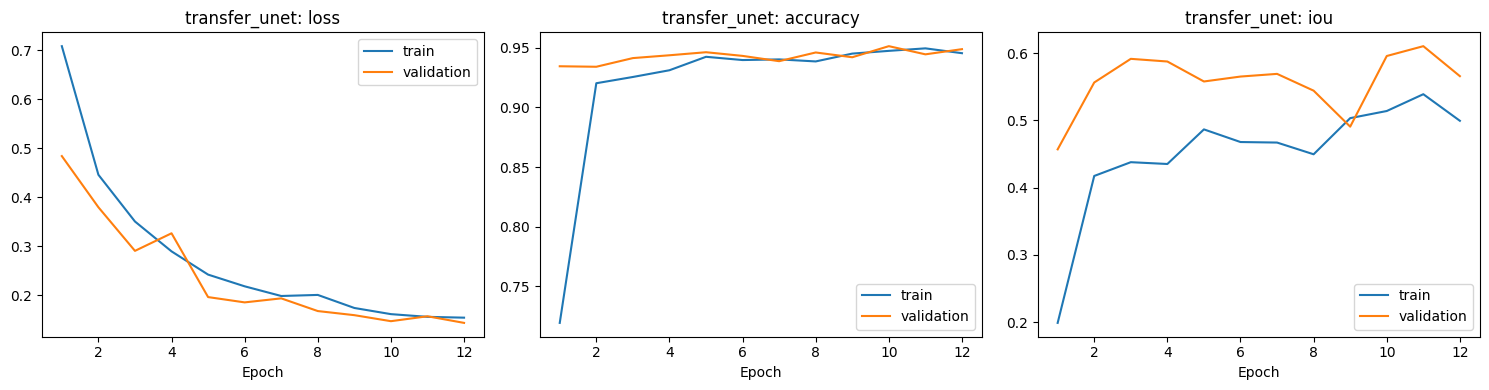

In [8]:
histories={}
for name,model in models.items():
    print('\nTraining:',name)
    model=model.to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=LR)
    best=-1.; history=[]
    for epoch in range(1,EPOCHS+1):
        tr_loss,tr=run_epoch(model,train_loader,optimizer)
        vl_loss,vl=run_epoch(model,val_loader)
        history.append({'epoch':epoch,'train_loss':tr_loss,'val_loss':vl_loss,'train_accuracy':tr['accuracy'],'val_accuracy':vl['accuracy'],'train_iou':tr['iou'],'val_iou':vl['iou']})
        print(f'{name} epoch {epoch}/{EPOCHS}: train loss {tr_loss:.4f}, val loss {vl_loss:.4f}, val IoU {vl["iou"]:.4f}, val Dice {vl["f1_dice"]:.4f}')
        if vl['iou']>best:
            best=vl['iou']; torch.save(model.state_dict(),OUT/f'{name}_best.pth')
    histories[name]=pd.DataFrame(history)
    histories[name].to_csv(OUT/f'{name}_history.csv',index=False)
    fig,ax=plt.subplots(1,3,figsize=(15,4))
    for j,key in enumerate(['loss','accuracy','iou']):
        ax[j].plot(histories[name]['epoch'],histories[name]['train_'+key],label='train')
        ax[j].plot(histories[name]['epoch'],histories[name]['val_'+key],label='validation')
        ax[j].set_title(f'{name}: {key}');ax[j].set_xlabel('Epoch');ax[j].legend()
    plt.tight_layout();plt.savefig(OUT/f'{name}_curves.png',dpi=180);plt.show()
    model.cpu();gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()

## 8. SAR threshold baseline (tuned ONLY using validation set)

Water often exhibits low backscatter in Sentinel-1 SAR imagery. The threshold is learned only on the validation partition. Evaluate the selected threshold on the untouched test set. This is a **simple low-VH threshold**, not NDWI (which requires optical bands).

  0%|          | 0/37 [00:00<?, ?it/s]

Validation-selected normalized VH threshold: 0.525 validation IoU: 0.5111925152080644


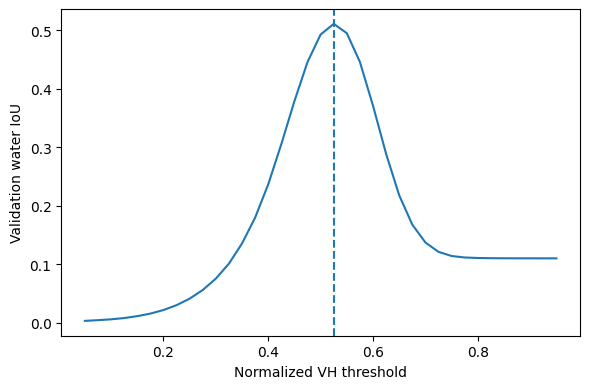

In [9]:
# Use normalized VH, second channel, for comparison (smaller value -> predicted water).
def threshold_conf(dataset,t):
    c=np.zeros(4,dtype=np.int64)
    for x,y in dataset:
        pred=(x[1].numpy()<t); gt=y.numpy(); good=gt!=-1;truth=gt==1
        c+=np.array([np.sum(~pred&~truth&good),np.sum(pred&~truth&good),np.sum(~pred&truth&good),np.sum(pred&truth&good)])
    return c
thresholds=np.linspace(.05,.95,37)
val_search=[(float(t),scores(threshold_conf(val_ds,float(t)))['iou']) for t in tqdm(thresholds)]
best_threshold,max_iou=max(val_search,key=lambda row:row[1])
print('Validation-selected normalized VH threshold:',best_threshold,'validation IoU:',max_iou)
plt.figure(figsize=(6,4));plt.plot([p[0] for p in val_search],[p[1] for p in val_search]);plt.axvline(best_threshold,ls='--');plt.xlabel('Normalized VH threshold');plt.ylabel('Validation water IoU');plt.tight_layout();plt.savefig(OUT/'baseline_threshold_tuning.png',dpi=180);plt.show()

## 9. Held-out test comparison, pixel-level confusion matrices and classification reports

  0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]

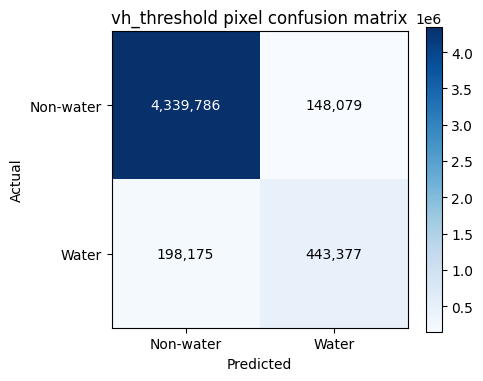

vh_threshold 
            precision    recall    support  f1-score
Non-water   0.956330  0.967005  4487865.0  0.961637
Water       0.749636  0.691101   641552.0  0.719179


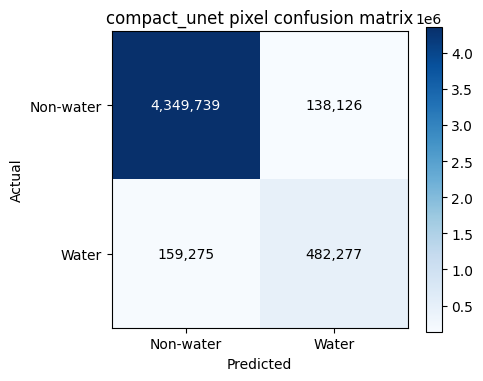

compact_unet 
            precision    recall    support  f1-score
Non-water   0.964676  0.969222  4487865.0  0.966944
Water       0.777361  0.751735   641552.0  0.764333


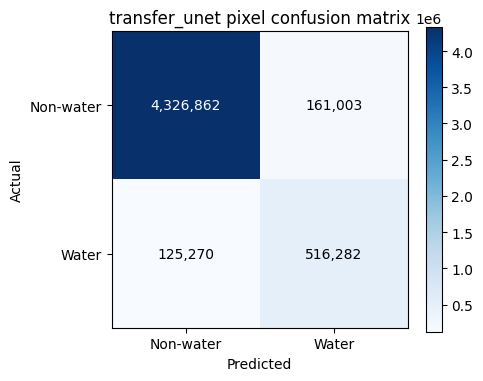

transfer_unet 
            precision    recall    support  f1-score
Non-water   0.971863  0.964125  4487865.0  0.967978
Water       0.762282  0.804739   641552.0  0.782935


,model,iou,f1_dice,accuracy,precision,recall
2,transfer_unet,0.643298,0.782935,0.944190,0.762282,0.804739
1,compact_unet,0.618559,0.764333,0.942021,0.777361,0.751735
0,vh_threshold,0.561499,0.719179,0.932496,0.749636,0.691101


All metrics are computed on the held-out test set only.


In [10]:
def eval_network(model,loader):
    conf=np.zeros(4,dtype=np.int64)
    model.eval()
    with torch.no_grad():
        for x,y in tqdm(loader,leave=False):
            conf+=accumulate_confusion(model(x.to(DEVICE)),y.to(DEVICE))
    return conf

all_conf={'vh_threshold':threshold_conf(test_ds,best_threshold)}
for name,model in models.items():
    model.load_state_dict(torch.load(OUT/f'{name}_best.pth',map_location='cpu',weights_only=True))
    model.to(DEVICE)
    all_conf[name]=eval_network(model,test_loader)
    model.cpu()
    if torch.cuda.is_available():torch.cuda.empty_cache()
rows=[]
for name,c in all_conf.items():
    s=scores(c);rows.append({'model':name,**s})
    mat=np.array([[s['tn'],s['fp']],[s['fn'],s['tp']]])
    fig,ax=plt.subplots(figsize=(5,4)); im=ax.imshow(mat,cmap='Blues')
    for (i,j),v in np.ndenumerate(mat):ax.text(j,i,f'{v:,}',ha='center',va='center',color='white' if v>mat.max()/2 else 'black')
    ax.set_xticks([0,1],['Non-water','Water']);ax.set_yticks([0,1],['Non-water','Water']);ax.set_xlabel('Predicted');ax.set_ylabel('Actual');ax.set_title(name+' pixel confusion matrix');plt.colorbar(im,ax=ax);plt.tight_layout();plt.savefig(OUT/f'{name}_confusion_matrix.png',dpi=180);plt.show()
    # Equivalent classification report computed from pixel-level confusion totals; avoids huge prediction arrays.
    tn,fp,fn,tp=map(int,c)
    report={'Non-water':{'precision':tn/(tn+fn) if tn+fn else 0,'recall':tn/(tn+fp) if tn+fp else 0,'support':tn+fp},
            'Water':{'precision':tp/(tp+fp) if tp+fp else 0,'recall':tp/(tp+fn) if tp+fn else 0,'support':tp+fn}}
    for k,v in report.items():v['f1-score']=2*v['precision']*v['recall']/(v['precision']+v['recall']) if v['precision']+v['recall'] else 0
    with open(OUT/f'{name}_classification_report.txt','w') as f:
        f.write('Pixel-level classification report (invalid labels excluded)\n'+pd.DataFrame(report).T.to_string())
    print(name,'\n',pd.DataFrame(report).T.to_string())
comparison=pd.DataFrame(rows).sort_values('iou',ascending=False)
comparison.to_csv(OUT/'model_comparison.csv',index=False)
display(comparison[['model','iou','f1_dice','accuracy','precision','recall']])
print('All metrics are computed on the held-out test set only.')

## 10. Prediction overlays, side-by-side mask comparison and optional error inspection

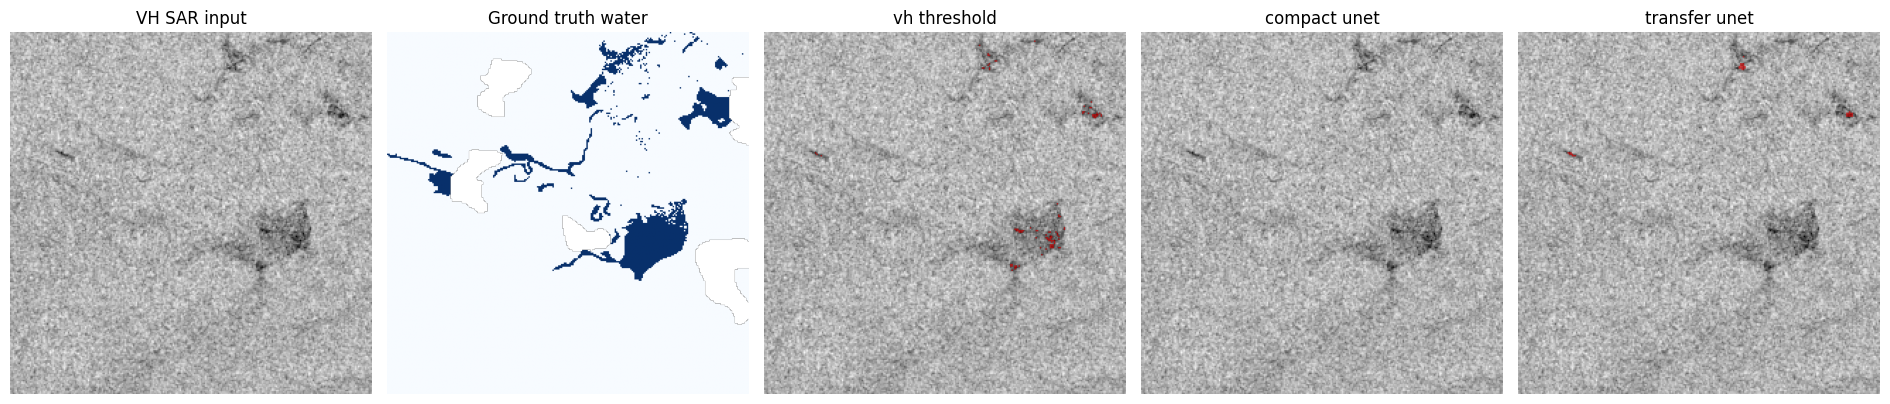

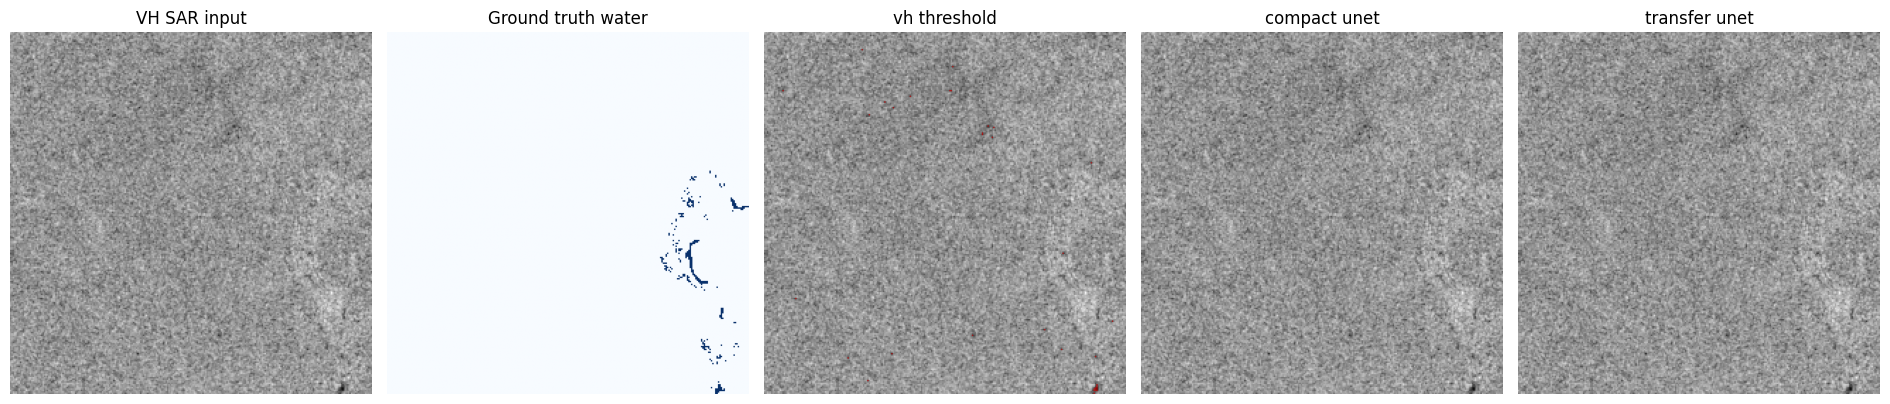

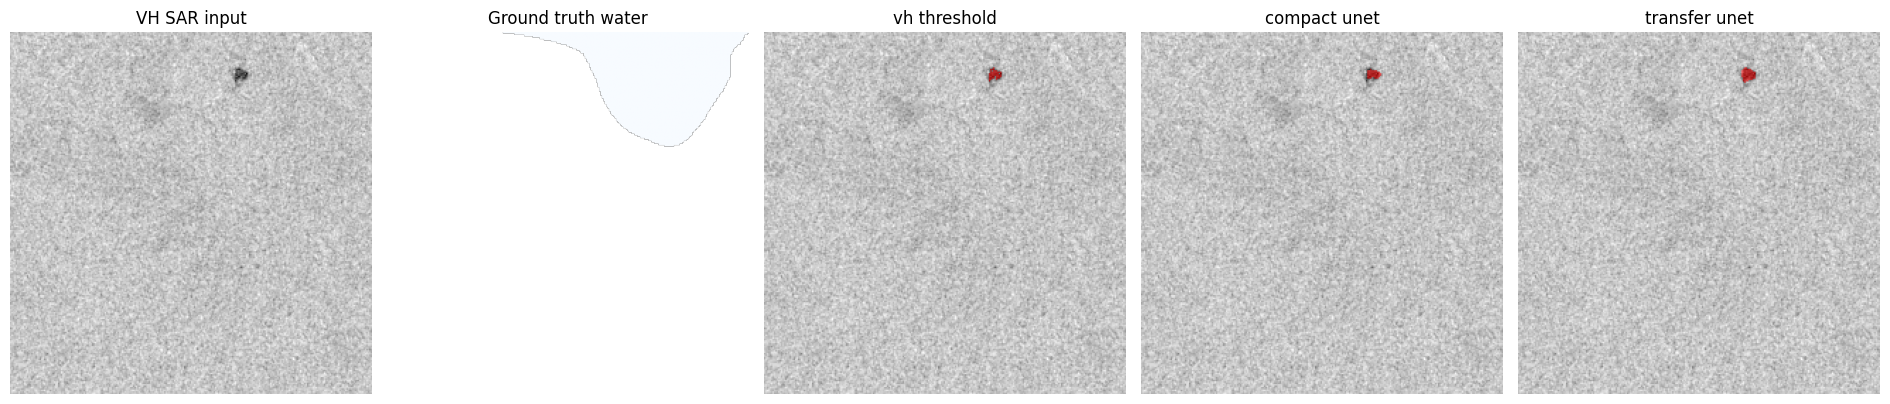

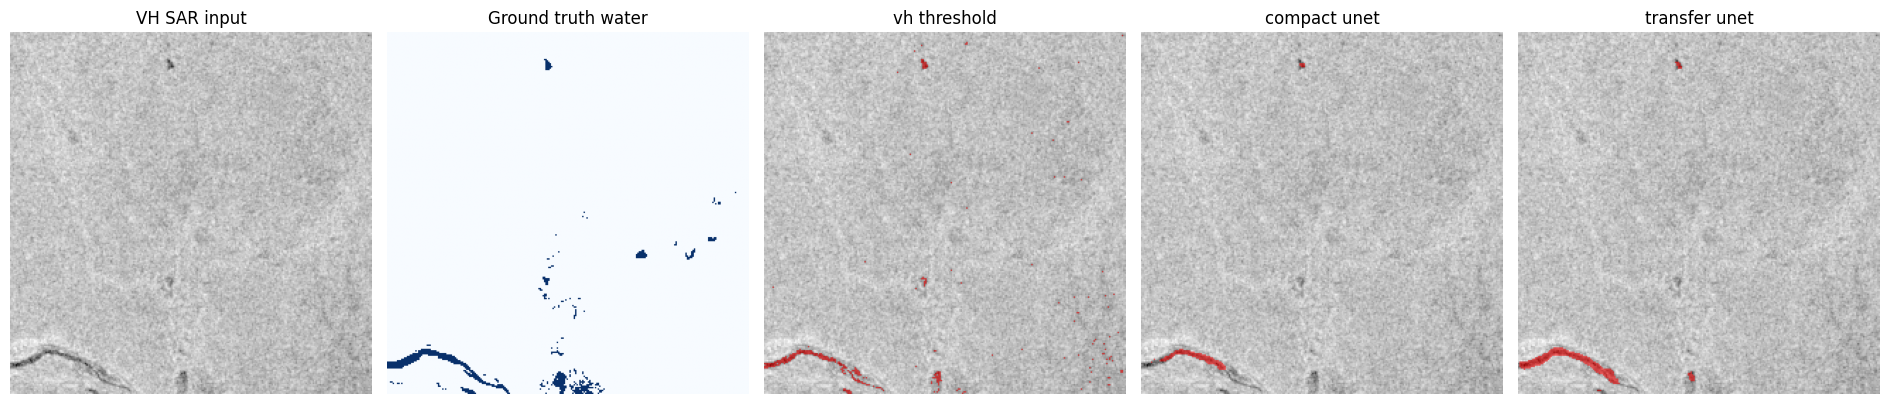

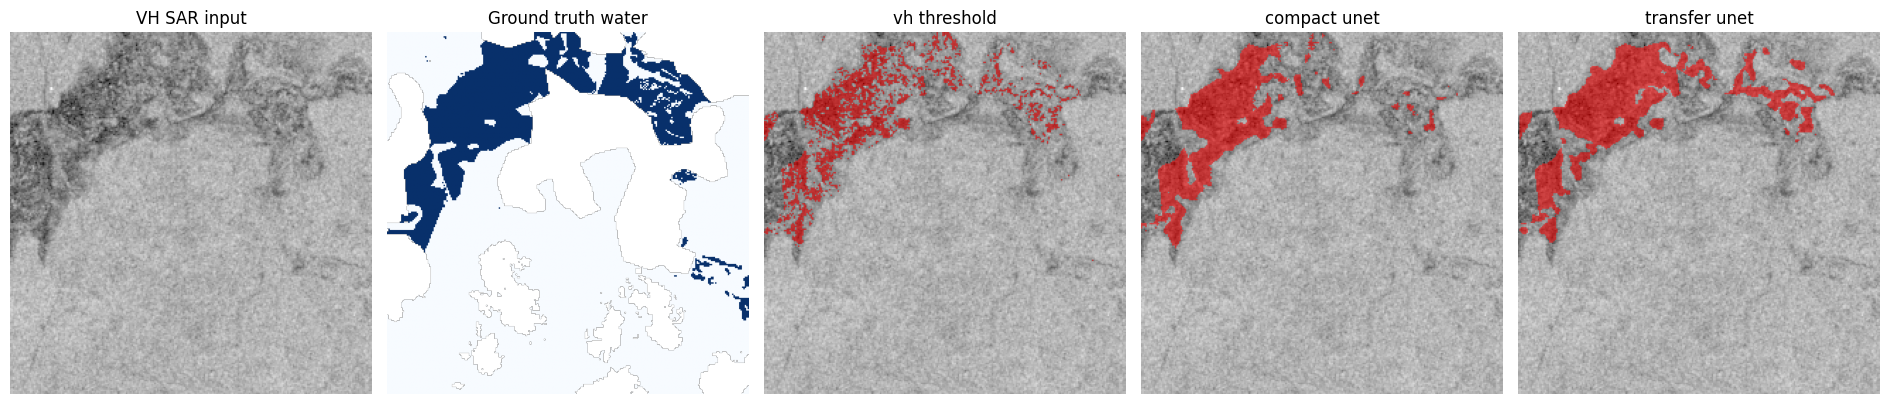

Figures and results saved to: /content/flood_mapping/outputs


In [11]:
def predict_binary(name,x):
    if name=='vh_threshold':return (x[1].numpy()<best_threshold).astype('uint8')
    model=models[name].to(DEVICE)
    model.eval()
    with torch.no_grad(): p=torch.sigmoid(model(x[None].to(DEVICE))[0,0]).cpu().numpy()>=.5
    model.cpu();return p.astype('uint8')

n=min(5,len(test_ds))
for idx in range(n):
    x,y=test_ds[idx];gt=y.numpy();base=x[1].numpy(); valid=gt!=-1
    fig,axs=plt.subplots(1,5,figsize=(19,4))
    axs[0].imshow(base,cmap='gray');axs[0].set_title('VH SAR input')
    axs[1].imshow(np.ma.masked_where(~valid,gt),vmin=0,vmax=1,cmap='Blues');axs[1].set_title('Ground truth water')
    for j,name in enumerate(['vh_threshold','compact_unet','transfer_unet'],start=2):
        pred=predict_binary(name,x)
        axs[j].imshow(base,cmap='gray')
        rgba=np.zeros((*pred.shape,4));rgba[...,0]=1.;rgba[...,3]=.55*(pred&valid)
        axs[j].imshow(rgba);axs[j].set_title(name.replace('_',' '))
    for a in axs:a.axis('off')
    plt.tight_layout();plt.savefig(OUT/f'test_overlay_{idx+1}.png',dpi=180,bbox_inches='tight');plt.show()
print('Figures and results saved to:',OUT)

## 11. Export results for the final Overleaf paper

The `outputs` directory contains dataset tables, models, baseline tuning, train/validation curves, three confusion matrices, three classification reports, model comparison and prediction overlays. Only use files produced by **your actual notebook run** as academic evidence.


In [12]:
metadata={'dataset':'Sen1Floods11 v1.1 hand-labelled Sentinel-1','seed':SEED,'image_size':SIZE,'batch_size':BATCH_SIZE,'epochs':EPOCHS,'learning_rate':LR,'device':DEVICE,'vh_threshold':best_threshold,'class_mapping':{'0':'non-water','1':'water','-1':'ignore'},'split_counts':{s:len(v) for s,v in splits.items()}}
(OUT/'run_metadata.json').write_text(json.dumps(metadata,indent=2))
archive=shutil.make_archive(str(ROOT/'flood_mapping_results'),'zip',OUT)
print('Results ZIP:',archive)
from IPython.display import display,FileLink
display(FileLink(archive))

Results ZIP: /content/flood_mapping/flood_mapping_results.zip


/content/flood_mapping/flood_mapping_results.zip

### Research validity and limitations
- This dataset marks **water/non-water**, not definitively *new floodwater vs permanent water*. State the proxy clearly.
- Original split uses official chip-level partition; spatial proximity between chips can still inflate transferability estimates.
- Hyperparameters and threshold should be selected with train/validation data only; test is evaluated once.
- `LabelHand=-1` is excluded from metrics and training loss.
- Accuracy is secondary to water IoU / Dice under class imbalance.
- Transfer learning here is **ImageNet-pretrained ResNet18 encoder**, fine-tuned on 2-channel SAR. Compare fairly using identical training settings.
- Training is designed for Colab GPU; download access and dependency availability must be verified in that live environment.